# Top 20% decline prediction: random forest + SHAP (second model)

**Purpose**: check the nonlinear relationships and feature interactions that logistic regression (first model) may miss,
and cross-check whether the results point in the same direction as the logistic ones.

**Considering the sample constraint**: with 499 households (223 declined) the sample is small, so to prevent tree overfitting
`max_depth` and `min_samples_leaf` are strongly restricted.

**First-model (logistic) results**: see `outputs/ml_logit_cv_summary.csv` and `outputs/ml_logit_odds_ratios.csv` (this notebook reads the CSVs in cell 7 to compare).

In [1]:
import pandas as pd
from config import DATA_DIR, OUT_DIR, INTERMEDIATE_DIR, FIG_DIR, SEED
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

candidates = ["Malgun Gothic", "NanumGothic", "AppleGothic"]
available = {f.name for f in fm.fontManager.ttflist}
font_name = next((c for c in candidates if c in available), None)
if font_name:
    plt.rcParams["font.family"] = font_name
plt.rcParams["axes.unicode_minus"] = False

pd.set_option('display.max_columns', 100)
RANDOM_STATE = SEED


## 1. Load the data (same final features as the logistic regression)

In [2]:
final_table = pd.read_csv(INTERMEDIATE_DIR / "h4_shrink_feature_table_final.csv", index_col=0).sort_index()
final_table.index.name = "HOUSEHOLD_KEY"

feature_cols_final = [c for c in final_table.columns if c != "label_shrink"]
X = final_table[feature_cols_final]
y = final_table["label_shrink"]

print(f"Number of features: {len(feature_cols_final)}")
print(f"Label distribution\n{y.value_counts()}")


Number of features: 18
Label distribution
label_shrink
0    276
1    223
Name: count, dtype: int64


## 2. Define the random forest (regularized for the sample constraint)

Tree-based models need no scaling, so the original features are used as is.
`max_depth=4` and `min_samples_leaf=15` strongly suppress overfitting (for a sample of 499 households).

In [3]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=15,
    max_features="sqrt",
    class_weight=None,  # the label ratio is 44.7:55.3, not a large imbalance
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


## 3. Cross-validated performance (same metrics as the logistic regression)

In [4]:
scoring = {
    "pr_auc": "average_precision",
    "recall": "recall",
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
}

cv_results = cross_validate(rf_model, X, y, cv=cv, scoring=scoring, return_train_score=False)

rf_results_summary = pd.DataFrame({
    "metric": list(scoring.keys()),
    "mean": [cv_results[f"test_{k}"].mean() for k in scoring],
    "std": [cv_results[f"test_{k}"].std() for k in scoring],
})
print("[Random forest] 5-fold cross-validation results")
print(rf_results_summary)

print("\n[Reference] Logistic regression results (previous notebook)")
lr_summary = pd.read_csv(OUT_DIR / "ml_logit_cv_summary.csv").set_index("metric")["mean"]
logistic_results = pd.DataFrame({
    "metric": ["pr_auc", "recall", "roc_auc", "accuracy"],
    "mean": [lr_summary[k] for k in ["pr_auc", "recall", "roc_auc", "accuracy"]],
})
print(logistic_results)


[Random forest] 5-fold cross-validation results
     metric      mean       std
0    pr_auc  0.656623  0.050386
1    recall  0.529192  0.072964
2   roc_auc  0.727729  0.041181
3  accuracy  0.657313  0.026366

[Reference] Logistic regression results (previous notebook)
     metric      mean
0    pr_auc  0.685158
1    recall  0.600606
2   roc_auc  0.737671
3  accuracy  0.683394


In [5]:
# --- source CSVs: random forest CV metrics (per fold, mean/std, next to the logistic means)
pd.DataFrame({"fold": range(1, 6), **{k: cv_results[f"test_{k}"] for k in scoring}}) \
    .to_csv(OUT_DIR / "ml_rf_cv_folds.csv", index=False)
rf_results_summary.assign(logit_mean=[lr_summary[k] for k in scoring]) \
    .to_csv(OUT_DIR / "ml_rf_cv_summary.csv", index=False)

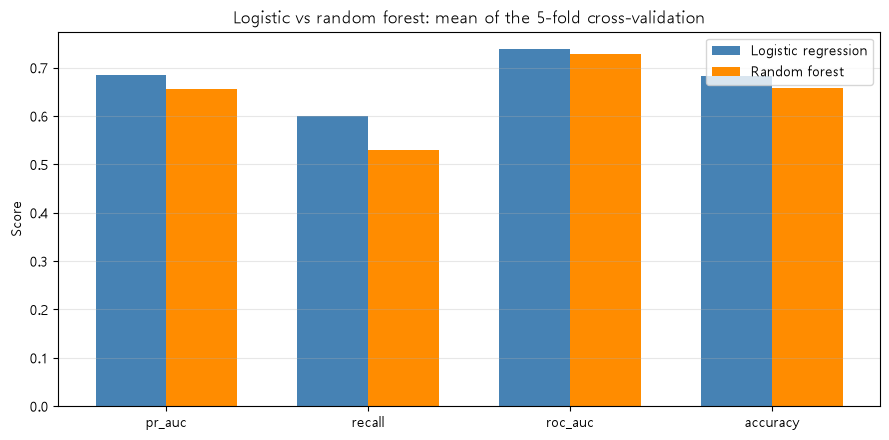

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(scoring))
width = 0.35

rf_means = [cv_results[f"test_{k}"].mean() for k in scoring]
lr_means = [lr_summary[k] for k in scoring]

ax.bar(x - width/2, lr_means, width, label="Logistic regression", color="steelblue")
ax.bar(x + width/2, rf_means, width, label="Random forest", color="darkorange")
ax.set_xticks(x)
ax.set_xticklabels(list(scoring.keys()))
ax.set_ylabel("Score")
ax.set_title("Logistic vs random forest: mean of the 5-fold cross-validation")
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()


## 4. Classification report + confusion matrix from out-of-fold predictions

In [7]:
y_pred = cross_val_predict(rf_model, X, y, cv=cv, method="predict")
y_proba = cross_val_predict(rf_model, X, y, cv=cv, method="predict_proba")[:, 1]

print("Classification report (0 = stayed, 1 = declined)")
print(classification_report(y, y_pred, target_names=["stayed (0)", "declined (1)"]))

cm = confusion_matrix(y, y_pred)
print("Confusion matrix")
print(pd.DataFrame(cm, index=["actual stayed", "actual declined"], columns=["predicted stayed", "predicted declined"]))


Classification report (0 = stayed, 1 = declined)
              precision    recall  f1-score   support

  stayed (0)       0.67      0.76      0.71       276
declined (1)       0.64      0.53      0.58       223

    accuracy                           0.66       499
   macro avg       0.65      0.65      0.65       499
weighted avg       0.66      0.66      0.65       499

Confusion matrix
                 predicted stayed  predicted declined
actual stayed                 210                  66
actual declined               105                 118


In [8]:
_tn, _fp, _fn, _tp = cm.ravel()
pd.DataFrame([{
    "tn": _tn, "fp": _fp, "fn": _fn, "tp": _tp, "n": len(y), "fn_rate_pct": _fn / (_fn + _tp) * 100,
    "recall": _tp / (_tp + _fn), "precision": _tp / (_tp + _fp), "threshold": 0.5,
}]).to_csv(OUT_DIR / "ml_rf_confusion.csv", index=False)

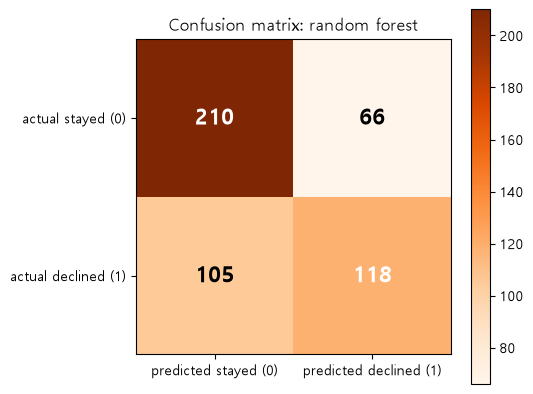

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap="Oranges")

labels_display = ["stayed (0)", "declined (1)"]
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels([f"predicted {l}" for l in labels_display])
ax.set_yticklabels([f"actual {l}" for l in labels_display])

for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center",
                 color="white" if cm[i, j] > cm.max()/2 else "black",
                 fontsize=16, fontweight="bold")

ax.set_title("Confusion matrix: random forest")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()


## 5. Final training on all the data (for SHAP interpretation)

**Note**: up to section 4 is for performance "evaluation" (validation predictions per fold); the model below is a separate one retrained on all the data for interpretation.

In [10]:
rf_model.fit(X, y)
print("Training done")


Training done


## 6. Compute the SHAP values

If the `shap` package is missing, install it with `pip install shap --break-system-packages`.

In [11]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
try:
    import shap
except ImportError:
    import subprocess
    subprocess.run(["pip", "install", "shap", "--break-system-packages", "-q"])
    import shap

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X)

# Handle versions where shap_values comes out as (n_samples, n_features, 2) in binary classification
if isinstance(shap_values, list):
    shap_values_pos = shap_values[1]  # for class 1 (decline)
elif shap_values.ndim == 3:
    shap_values_pos = shap_values[:, :, 1]
else:
    shap_values_pos = shap_values

print(f"shap_values shape: {shap_values_pos.shape}")


shap_values shape: (499, 18)


In [12]:
pd.DataFrame(shap_values_pos, columns=feature_cols_final, index=X.index) \
    .to_csv(INTERMEDIATE_DIR / "ml_shap_values.csv", index_label="household_key")

## 7. SHAP summary plot: global feature importance (bars)

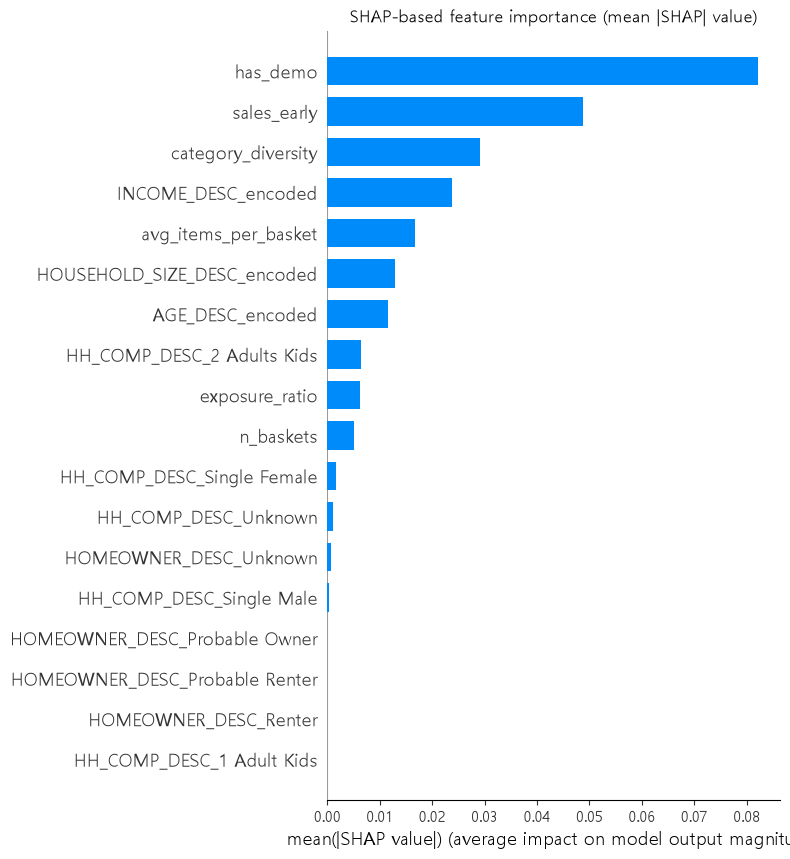

In [13]:
shap.summary_plot(shap_values_pos, X, plot_type="bar", show=False)
plt.title("SHAP-based feature importance (mean |SHAP| value)")
plt.tight_layout()
plt.show()


## 8. SHAP beeswarm: detailed distribution including direction

Each dot is one household. Color is the size of the feature value (red = high, blue = low), and the x position is that household's contribution to the decline (1) prediction.

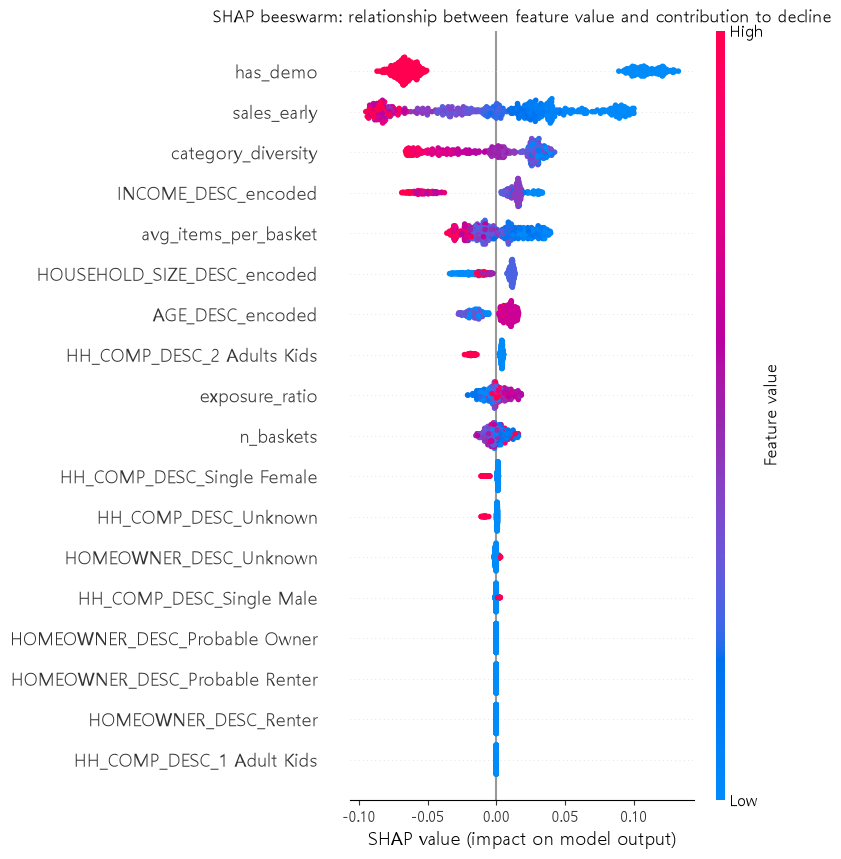

In [14]:
shap.summary_plot(shap_values_pos, X, show=False)
plt.title("SHAP beeswarm: relationship between feature value and contribution to decline")
plt.tight_layout()
plt.show()


## 9. Top 3 features: dependence plots (checking nonlinear relationships)

For the 3 features with the highest SHAP importance, check whether the contribution to decline (the SHAP value) changes linearly as the value changes,
or bends sharply in some range. This is what logistic regression (a linear assumption) may miss.

In [15]:
mean_abs_shap = np.abs(shap_values_pos).mean(axis=0)
top3_features = pd.Series(mean_abs_shap, index=feature_cols_final).sort_values(ascending=False, kind="stable").head(3)
print("Top 3 features by SHAP")
print(top3_features)


Top 3 features by SHAP
has_demo              0.082251
sales_early           0.048776
category_diversity    0.029163
dtype: float64


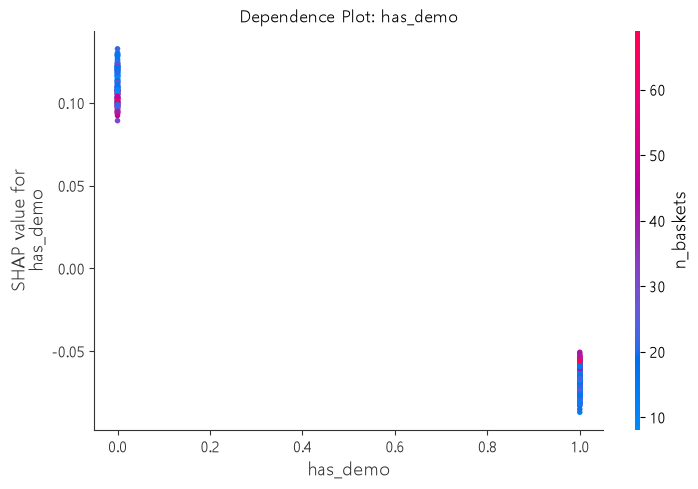

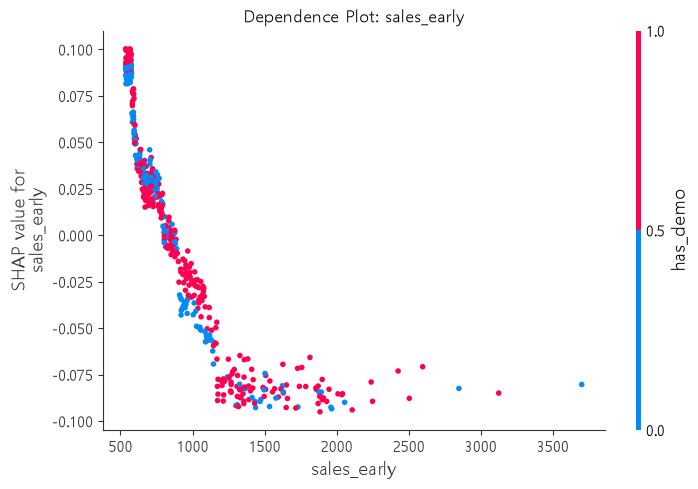

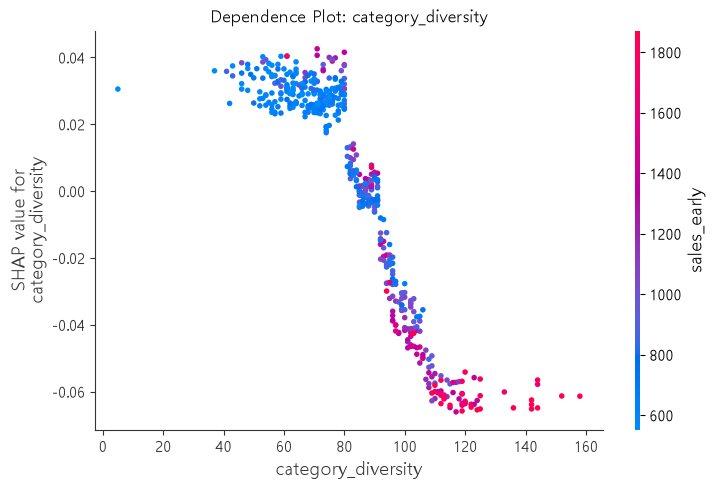

In [16]:
for feat in top3_features.index:
    shap.dependence_plot(feat, shap_values_pos, X, show=False)
    plt.title(f"Dependence Plot: {feat}")
    plt.tight_layout()
    plt.show()


In [17]:
# --- dependence-plot data (per household, intermediate)
pd.concat([pd.DataFrame({"feature": f, "feature_value": X[f].values,
                         "shap_value": shap_values_pos[:, feature_cols_final.index(f)]})
           for f in top3_features.index]).to_csv(INTERMEDIATE_DIR / "ml_shap_dependence.csv", index=False)

In [18]:
# --- source CSV: SHAP saturation, mean SHAP by decile of each top-3 feature value
_rows = []
for f in top3_features.index:
    _s = pd.DataFrame({"x": X[f].values, "shap": shap_values_pos[:, feature_cols_final.index(f)]})
    _s["bin"] = pd.qcut(_s["x"], 10, duplicates="drop")
    _g = _s.groupby("bin", observed=True).agg(n_households=("x", "size"), feature_min=("x", "min"),
                                              feature_max=("x", "max"), feature_mean=("x", "mean"),
                                              mean_shap=("shap", "mean")).reset_index(drop=True)
    _g.insert(0, "decile", range(1, len(_g) + 1))
    _g.insert(0, "feature", f)
    _rows.append(_g)
pd.concat(_rows).to_csv(OUT_DIR / "ml_shap_saturation_deciles.csv", index=False)

## 10. Logistic vs random forest: direction comparison table

Check whether the logistic odds ratios (positive coefficient = risk, negative = protective) and the direction of the mean SHAP contribution agree.

In [19]:
# Mean SHAP value of each feature (signed): positive = toward decline risk, negative = protective
mean_shap_signed = shap_values_pos.mean(axis=0)

comparison = pd.DataFrame({
    "feature": feature_cols_final,
    "mean_abs_shap": mean_abs_shap,
    "mean_signed_shap": mean_shap_signed,
    "rf_direction": np.where(mean_shap_signed > 0, "risk (decline up)", "protective (decline down)"),
}).sort_values("mean_abs_shap", ascending=False, kind="stable")

print(comparison.to_string(index=False))


                       feature  mean_abs_shap  mean_signed_shap              rf_direction
                      has_demo       0.082251         -0.002924 protective (decline down)
                   sales_early       0.048776         -0.001307 protective (decline down)
            category_diversity       0.029163          0.000559         risk (decline up)
           INCOME_DESC_encoded       0.023791          0.000114         risk (decline up)
          avg_items_per_basket       0.016743          0.000527         risk (decline up)
   HOUSEHOLD_SIZE_DESC_encoded       0.012897          0.001117         risk (decline up)
              AGE_DESC_encoded       0.011536          0.001153         risk (decline up)
    HH_COMP_DESC_2 Adults Kids       0.006349          0.000395         risk (decline up)
                exposure_ratio       0.006204         -0.000169 protective (decline down)
                     n_baskets       0.005189          0.000187         risk (decline up)
    HH_COM

In [20]:
# --- source CSV: SHAP summary (global importance and mean signed contribution)
comparison.reset_index(drop=True).rename_axis("rank").reset_index().assign(rank=lambda d: d["rank"] + 1) \
    .to_csv(OUT_DIR / "ml_shap_summary.csv", index=False)

## 11. Interpretation guide

- **Performance (section 4 vs logistic)**: if the random forest is clearly better than logistic, nonlinearity/interactions really exist;
  if it is similar or worse, the relationships in this data are mostly linear (with a small sample, trees may not have the advantage)
- **SHAP importance ranking**: if it largely matches the logistic odds-ratio ranking, the two models have reconfirmed each other's results
- **If the directions disagree**: in particular, if a feature such as `exposure_ratio`, which was nearly neutral in the logistic model, shows up
  strongly in SHAP, it may be an **interaction** effect with other variables (e.g. exposure is related to decline only in a certain income band)
  -> check in the dependence plot whether the pattern splits by color (the value of another feature)
- **When writing the final conclusion**: describe the features that both models point to (e.g. sales_early, category_diversity, has_demo)
  as the core signals, and the features that appear in only one as "exploratory signals needing further verification given the sample constraint"